# CRISP-DM: Telco Customer Churn

## Business Understanding
A telecom provider wants to identify customers likely to churn so retention teams can prioritize outreach. Success is a validated model and a practical deployment plan.

## Data Understanding
We use IBM's public Telco Customer Churn dataset. The target is `Churn`. We inspect shape, types, missing values, duplicates, class balance, and relationships between contract type and churn.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
url='https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df=pd.read_csv(url)
print(df.shape); display(df.head()); display(df['Churn'].value_counts(normalize=True))

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,proportion
Churn,
No,0.73463
Yes,0.26537


,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0


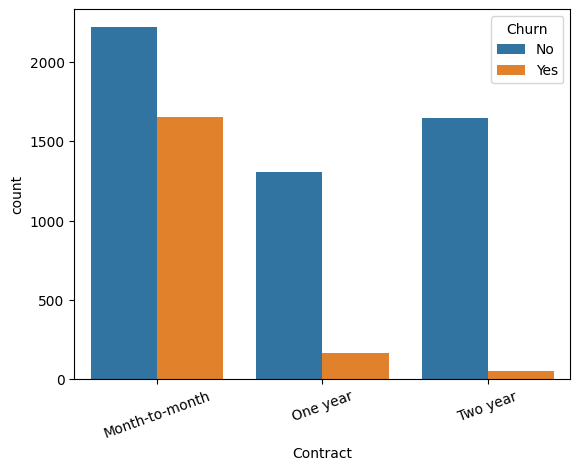

In [2]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
display(df.isna().sum().sort_values(ascending=False).head())
sns.countplot(data=df,x='Contract',hue='Churn'); plt.xticks(rotation=20); plt.show()

## Data Preparation
Remove the identifier, convert `TotalCharges`, impute missing values, scale numeric columns, and one-hot encode categorical columns. Use a stratified train/test split to preserve churn prevalence.

In [3]:
X=df.drop(columns=['Churn','customerID']); y=(df['Churn']=='Yes').astype(int)
num=X.select_dtypes(include=np.number).columns; cat=X.select_dtypes(exclude=np.number).columns
prep=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cat)])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)

## Modeling and Evaluation
Logistic regression is selected for interpretability and class weighting. ROC-AUC and recall are emphasized because missing a potential churner may be costly.

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.841


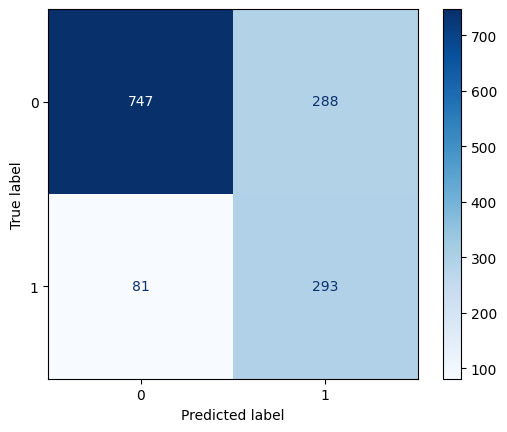

In [4]:
model=Pipeline([('prep',prep),('model',LogisticRegression(max_iter=1000,class_weight='balanced'))])
model.fit(Xtr,ytr); pred=model.predict(Xte); prob=model.predict_proba(Xte)[:,1]
print(classification_report(yte,pred)); print('ROC-AUC:',round(roc_auc_score(yte,prob),3))
ConfusionMatrixDisplay.from_predictions(yte,pred,cmap='Blues'); plt.show()

## Deployment
Deploy as a weekly batch-scoring workflow. Send high-probability customers to a retention queue, select the threshold using campaign costs, and monitor recall, ROC-AUC, feature drift, and campaign outcomes. Human review is required before customer action.

## Limitations
This model predicts association, not whether an offer causes retention. The data are historical, behavior may drift, and class imbalance can affect metrics. Future work should use time-based validation and uplift experiments.

## Expanded Data Quality Audit

A defensible CRISP-DM project documents data quality before modeling. We check missingness, duplicates, invalid values, target balance, and whether any identifier could leak information into the model.

In [5]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2),
    "unique_values": df.nunique()
}).sort_values("missing_pct", ascending=False)
display(quality)
print("Rows:", len(df), "Columns:", len(df.columns))
print("Duplicate rows:", df.duplicated().sum())
print("TotalCharges invalid/blank values after numeric conversion:", df["TotalCharges"].isna().sum())

,dtype,missing_count,missing_pct,unique_values
TotalCharges,float64,11,0.16,6530
gender,object,0,0.00,2
SeniorCitizen,int64,0,0.00,2
Partner,object,0,0.00,2
customerID,object,0,0.00,7043
Dependents,object,0,0.00,2
tenure,int64,0,0.00,73
MultipleLines,object,0,0.00,3
PhoneService,object,0,0.00,2
OnlineSecurity,object,0,0.00,3


Rows: 7043 Columns: 21
Duplicate rows: 0
TotalCharges invalid/blank values after numeric conversion: 11


## Expanded Exploratory Analysis

The following analysis examines numerical distributions and churn rates across important business variables. Each chart is followed by a business interpretation rather than being included without context.

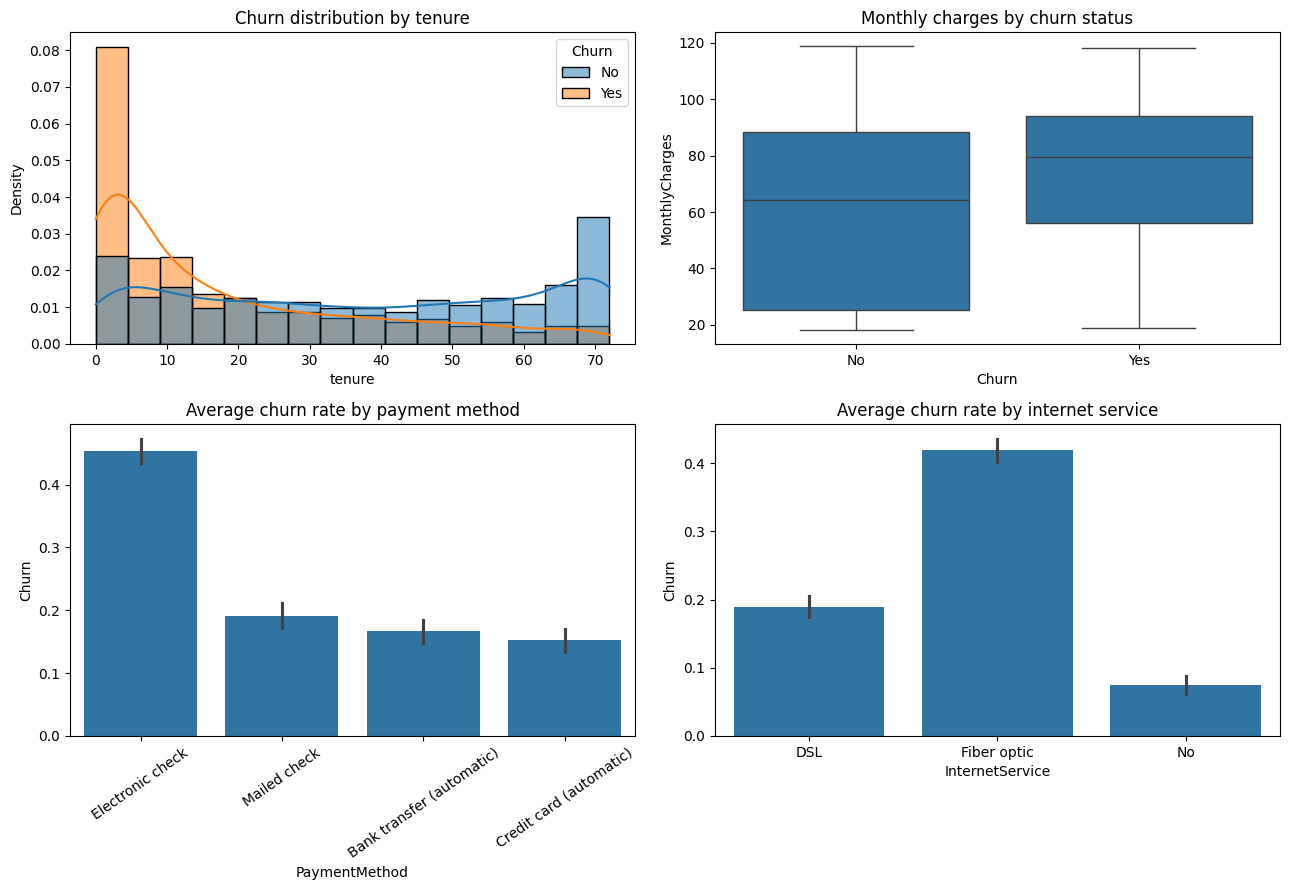

Interpretation: churn is generally concentrated among shorter-tenure customers and varies across service and payment groups; these patterns motivate retention targeting but do not prove causation.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, stat="density", common_norm=False, ax=axes[0,0])
axes[0,0].set_title("Churn distribution by tenure")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0,1])
axes[0,1].set_title("Monthly charges by churn status")
sns.barplot(data=df, x="PaymentMethod", y=df["Churn"].eq("Yes"), ax=axes[1,0])
axes[1,0].set_title("Average churn rate by payment method"); axes[1,0].tick_params(axis="x", rotation=35)
sns.barplot(data=df, x="InternetService", y=df["Churn"].eq("Yes"), ax=axes[1,1])
axes[1,1].set_title("Average churn rate by internet service")
plt.tight_layout(); plt.show()
print("Interpretation: churn is generally concentrated among shorter-tenure customers and varies across service and payment groups; these patterns motivate retention targeting but do not prove causation.")

## Baseline, Model Comparison, and Cross-Validation

A majority-class baseline establishes the minimum useful performance. Two different model families are compared, and cross-validation estimates stability beyond a single train/test split.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
baseline = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
print("Baseline accuracy:", round(baseline.score(Xte, yte), 3))
comparison = {
    "Logistic Regression": model,
    "Random Forest": Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=250, random_state=42, class_weight="balanced"))])
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, candidate in comparison.items():
    scores = cross_validate(candidate, X, y, cv=cv, scoring={"roc_auc":"roc_auc", "recall":"recall", "f1":"f1"})
    print(name, "CV ROC-AUC", round(scores["test_roc_auc"].mean(),3), "CV recall", round(scores["test_recall"].mean(),3), "CV F1", round(scores["test_f1"].mean(),3))

Baseline accuracy: 0.735
Logistic Regression CV ROC-AUC 0.845 CV recall 0.801 CV F1 0.626
Random Forest CV ROC-AUC 0.821 CV recall 0.478 CV F1 0.542


## Error Analysis and Feature Interpretation

False negatives are especially important because they are customers the model fails to flag before churn. Threshold selection should therefore be based on the cost of missed churn and unnecessary offers, not accuracy alone.

In [8]:
error_table = Xte.copy()
error_table["actual_churn"] = yte.values
error_table["predicted_churn"] = pred
error_table["predicted_probability"] = prob
display(error_table[error_table["actual_churn"] != error_table["predicted_churn"]].head(10))
for threshold in [.30, .40, .50, .60]:
    threshold_pred = (prob >= threshold).astype(int)
    print("threshold", threshold, "precision", round(precision_score(yte, threshold_pred),3), "recall", round(recall_score(yte, threshold_pred),3), "F1", round(f1_score(yte, threshold_pred),3))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual_churn,predicted_churn,predicted_probability
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.853079
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,1,0.660663
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,0,1,0.806060
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,0,1,0.698471
2079,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,106.05,7554.05,0,1,0.517908
2136,Male,0,No,Yes,15,Yes,Yes,Fiber optic,No,Yes,...,Yes,No,Month-to-month,Yes,Electronic check,91.00,1430.05,0,1,0.820421
1242,Female,0,Yes,No,21,No,No phone service,DSL,Yes,No,...,No,No,Month-to-month,No,Electronic check,28.50,629.35,0,1,0.509951
1838,Male,1,No,No,54,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Month-to-month,Yes,Electronic check,90.05,4931.80,0,1,0.704284
6979,Male,0,No,Yes,1,No,No phone service,DSL,No,No,...,No,No,Month-to-month,No,Mailed check,24.20,24.20,0,1,0.664771
3624,Female,1,Yes,Yes,62,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Month-to-month,Yes,Credit card (automatic),96.10,6019.35,0,1,0.501674


threshold 0.3 precision 0.429 recall 0.928 F1 0.587
threshold 0.4 precision 0.466 recall 0.866 F1 0.606
threshold 0.5 precision 0.504 recall 0.783 F1 0.614
threshold 0.6 precision 0.54 recall 0.706 F1 0.612


## CRISP-DM Decision Record

**Business understanding:** prioritize retention resources. **Data understanding:** churn is imbalanced and customer behavior varies by tenure, service, and payment method. **Preparation:** clean numeric fields and encode categories inside a pipeline. **Modeling:** compare an interpretable linear model with a nonlinear ensemble. **Evaluation:** use ROC-AUC, recall, F1, cross-validation, and threshold analysis. **Deployment:** batch-score customers weekly, monitor drift, and measure retention uplift. This traceability connects each technical choice to a business decision.

## Deployment Artifact Specification

A production implementation should include: (1) versioned preprocessing and model pipeline, (2) a weekly input schema check, (3) probability scores and model version in the output table, (4) a threshold configuration owned by the retention team, (5) monitoring dashboards for drift and recall, and (6) a rollback path. The notebook demonstrates the scoring function but does not claim that a live service has been deployed.